# Practical No. 08 — High-Performance Big Data Analytics Using R
**Name:** Tanishq Kulkarni  
**Roll No.:** 24102A2007  
**Dataset:** NYC TLC Yellow Taxi Trip Records (January–March 2024)

## Aim
Analyze large-scale NYC taxi trip records in R using `data.table`, functional/vectorized operations, sequential and parallel computing, performance benchmarking, and visualizations.

**Source:** [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page). Three monthly Yellow Taxi Parquet files and the official taxi zone lookup are used. A reproducible sample from each month limits Colab memory usage.

In [ ]:
options(repos = c(CRAN = "https://cloud.r-project.org"))
packages <- c("data.table", "ggplot2", "foreach", "doParallel", "arrow")
missing <- packages[!vapply(packages, requireNamespace, logical(1), quietly = TRUE)]
if (length(missing)) install.packages(missing, quiet = TRUE)
invisible(lapply(packages, library, character.only = TRUE))
set.seed(42)

also installing the dependencies ‘iterators’, ‘assertthat’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp




## 1. Data acquisition and preparation

In [ ]:
dir.create("taxi_data", showWarnings = FALSE)
months <- c("2024-01", "2024-02", "2024-03")
files <- file.path("taxi_data", paste0("yellow_tripdata_", months, ".parquet"))
for (i in seq_along(files)) {
  if (!file.exists(files[i])) {
    download.file(
      paste0("https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_", months[i], ".parquet"),
      files[i], mode = "wb", quiet = TRUE
    )
  }
}
zone_file <- "taxi_data/taxi_zone_lookup.csv"
if (!file.exists(zone_file)) {
  download.file("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv", zone_file, mode = "wb", quiet = TRUE)
}
file.info(files)[, c("size") , drop = FALSE]

,size
,<dbl>
taxi_data/yellow_tripdata_2024-01.parquet,49961641
taxi_data/yellow_tripdata_2024-02.parquet,50349284
taxi_data/yellow_tripdata_2024-03.parquet,60078280


In [ ]:
wanted <- c("tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "passenger_count", "trip_distance", "payment_type", "fare_amount", "tip_amount", "tolls_amount", "total_amount")
read_month <- function(path, n = 100000L) {
  x <- as.data.table(arrow::read_parquet(path, col_select = wanted))
  if (nrow(x) > n) x <- x[sample.int(nrow(x), n)]
  x
}
trips <- rbindlist(lapply(files, read_month), use.names = TRUE, fill = TRUE)
cat("Imported rows:", nrow(trips), " | Columns:", ncol(trips), "\n")
print(str(trips))
summary(trips[, .(trip_distance, fare_amount, total_amount, passenger_count)])

Warning message:
“Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(wanted)

  # Now:
  data %>% select(all_of(wanted))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.”


Imported rows: 300000  | Columns: 11 
Classes ‘data.table’ and 'data.frame':	300000 obs. of  11 variables:
 $ tpep_pickup_datetime : POSIXct, format: "2024-01-01 17:03:06" "2024-01-08 15:37:48" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2024-01-01 17:14:20" "2024-01-08 15:43:06" ...
 $ PULocationID         : int  151 161 75 43 161 239 132 132 140 68 ...
 $ DOLocationID         : int  163 161 140 161 170 163 142 122 263 113 ...
 $ passenger_count      : int  4 5 1 1 2 NA 2 1 1 2 ...
 $ trip_distance        : num  2.59 0.27 1.8 1.7 0.77 1.89 22.2 4.69 0.94 1.8 ...
 $ payment_type         : int  1 2 1 1 1 0 1 2 1 1 ...
 $ fare_amount          : num  14.2 6.5 11.4 12.8 8.6 ...
 $ tip_amount           : num  3.64 0 2 2 2.5 ...
 $ tolls_amount         : num  0 0 0 0 0 0 6.94 0 0 0 ...
 $ total_amount         : num  21.8 10.5 18.4 19.8 15.1 ...
 - attr(*, ".internal.selfref")=<pointer: 0x5b43d6bad3f0> 
NULL


 trip_distance        fare_amount       total_amount     passenger_count
 Min.   :    0.000   Min.   :-300.00   Min.   :-302.75   Min.   :0.000  
 1st Qu.:    1.000   1st Qu.:   8.60   1st Qu.:  15.45   1st Qu.:1.000  
 Median :    1.700   Median :  12.80   Median :  20.16   Median :1.000  
 Mean   :    3.668   Mean   :  18.26   Mean   :  26.78   Mean   :1.333  
 3rd Qu.:    3.160   3rd Qu.:  20.50   3rd Qu.:  28.92   3rd Qu.:1.000  
 Max.   :51621.570   Max.   : 800.00   Max.   : 801.00   Max.   :9.000  
                                                         NAs    :22945  

In [ ]:
before <- nrow(trips)
trips <- unique(trips)
trips <- trips[!is.na(tpep_pickup_datetime) & !is.na(tpep_dropoff_datetime) &
               !is.na(PULocationID) & !is.na(DOLocationID) &
               !is.na(trip_distance) & !is.na(fare_amount) & !is.na(total_amount) &
               trip_distance > 0 & trip_distance <= 100 &
               fare_amount >= 0 & total_amount > 0 & total_amount < 1000 &
               tpep_dropoff_datetime > tpep_pickup_datetime]
trips[, pickup_time := as.POSIXct(tpep_pickup_datetime, tz = "America/New_York")]
trips <- trips[format(pickup_time, "%Y-%m") %in% months]
trips[, `:=`(hour = as.integer(format(pickup_time, "%H")),
             day = as.integer(format(pickup_time, "%d")),
             weekday = factor(weekdays(pickup_time),
                              levels = c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday")),
             month = format(pickup_time, "%Y-%m"))]
trips[, c("tpep_pickup_datetime", "tpep_dropoff_datetime", "pickup_time") := NULL]
cat("Original:", before, " | Clean:", nrow(trips), " | Removed:", before - nrow(trips), "\n")
print(round(as.numeric(object.size(trips)) / 1024^2, 2))

Original: 300000  | Clean: 288007  | Removed: 11993 
[1] 20.88


In [ ]:
zones <- fread(zone_file)
pickup_zones <- zones[, .(PULocationID = LocationID, pickup_zone = Zone, pickup_borough = Borough)]
dropoff_zones <- zones[, .(DOLocationID = LocationID, dropoff_zone = Zone, dropoff_borough = Borough)]
trips <- merge(trips, pickup_zones, by = "PULocationID", all.x = TRUE, sort = FALSE)
trips <- merge(trips, dropoff_zones, by = "DOLocationID", all.x = TRUE, sort = FALSE)
trips[is.na(pickup_zone), pickup_zone := "Unknown"]
trips[is.na(dropoff_zone), dropoff_zone := "Unknown"]
trips[is.na(pickup_borough), pickup_borough := "Unknown"]
trips[is.na(dropoff_borough), dropoff_borough := "Unknown"]
head(trips[, .(pickup_zone, dropoff_zone, month, hour, trip_distance, total_amount)])

pickup_zone,dropoff_zone,month,hour,trip_distance,total_amount
<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>
Manhattan Valley,Midtown North,2024-01,12,2.59,21.84
Midtown Center,Midtown Center,2024-01,10,0.27,10.50
East Harlem South,Lenox Hill East,2024-01,16,1.80,18.40
Central Park,Midtown Center,2024-01,16,1.70,19.80
Midtown Center,Murray Hill,2024-01,9,0.77,15.10
Upper West Side South,Midtown North,2024-01,10,1.89,19.32


## 2. Transportation analytics

In [ ]:
hourly <- trips[, .(trips = .N, revenue = sum(total_amount), avg_fare = mean(fare_amount)), by = hour][order(hour)]
daily <- trips[, .(trips = .N, avg_fare = mean(fare_amount)), by = weekday][order(weekday)]
monthly <- trips[, .(trips = .N, revenue = sum(total_amount), avg_fare = mean(fare_amount)), by = month][order(month)]
routes <- trips[, .(trips = .N, revenue = sum(total_amount)), by = .(pickup_zone, dropoff_zone)][order(-trips)]
revenue_routes <- routes[order(-revenue)]
payments <- trips[, .N, by = .(pickup_borough, payment_type)][order(-N)]
cat("Hourly demand\n"); print(hourly)
cat("Day-of-week demand\n"); print(daily)
cat("Monthly summary\n"); print(monthly)
cat("Top routes by volume\n"); print(head(routes, 10))
cat("Top routes by revenue\n"); print(head(revenue_routes, 10))
cat("Payment methods by borough\n"); print(head(payments, 12))

Hourly demand
     hour trips   revenue avg_fare
    <int> <int>     <num>    <num>
 1:     0  1767  63285.52 26.16380
 2:     1  3337 103620.41 22.64829
 3:     2  7133 192928.27 19.26472
 4:     3 10430 266311.28 17.91110
 5:     4 12114 312726.95 18.00131
 6:     5 12857 332776.78 17.93247
 7:     6 13947 361830.45 18.01019
 8:     7 15291 398040.33 18.06117
 9:     8 16277 445989.32 19.14969
10:     9 16911 473129.55 19.60744
11:    10 17653 492762.39 19.58581
12:    11 18000 541215.27 20.09956
13:    12 19266 550562.86 18.57614
14:    13 20750 568754.11 17.63953
15:    14 18772 514240.45 17.64994
16:    15 16736 457711.31 18.07216
17:    16 16546 448623.14 18.18700
18:    17 15435 422601.39 18.48935
19:    18 12344 353573.58 19.68729
20:    19  8729 249106.26 19.69081
21:    20  5817 149746.92 17.65125
22:    21  3824  91729.25 16.28332
23:    22  2484  62266.41 17.13370
24:    23  1587  46389.96 20.77474
     hour trips   revenue avg_fare
    <int> <int>     <num>    <num>
Day-of

## 3. Visualizations

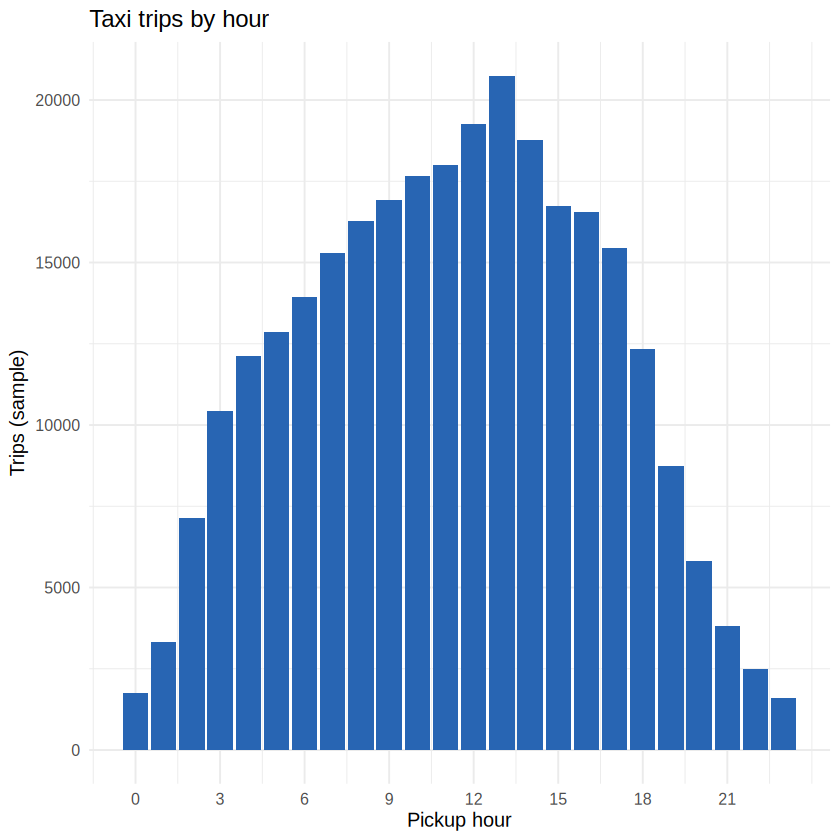

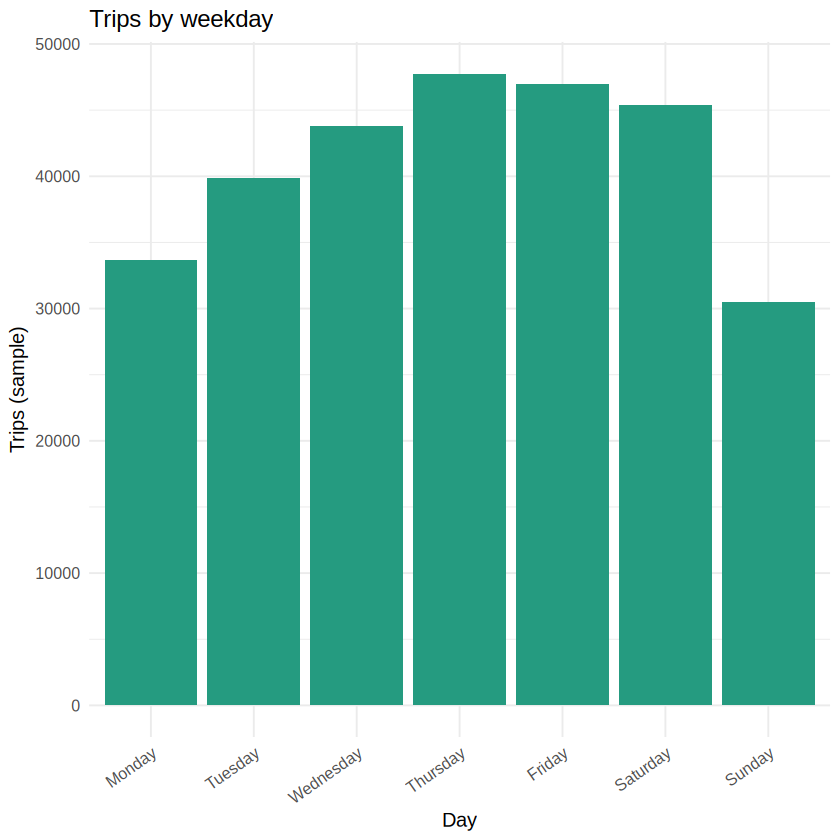

In [ ]:
theme_set(theme_minimal(base_size = 12))
ggplot(hourly, aes(hour, trips)) + geom_col(fill = "#2865b3") +
  scale_x_continuous(breaks = seq(0, 23, 3)) + labs(title = "Taxi trips by hour", x = "Pickup hour", y = "Trips (sample)")
ggplot(daily, aes(weekday, trips)) + geom_col(fill = "#259b80") +
  labs(title = "Trips by weekday", x = "Day", y = "Trips (sample)") + theme(axis.text.x = element_text(angle = 35, hjust = 1))

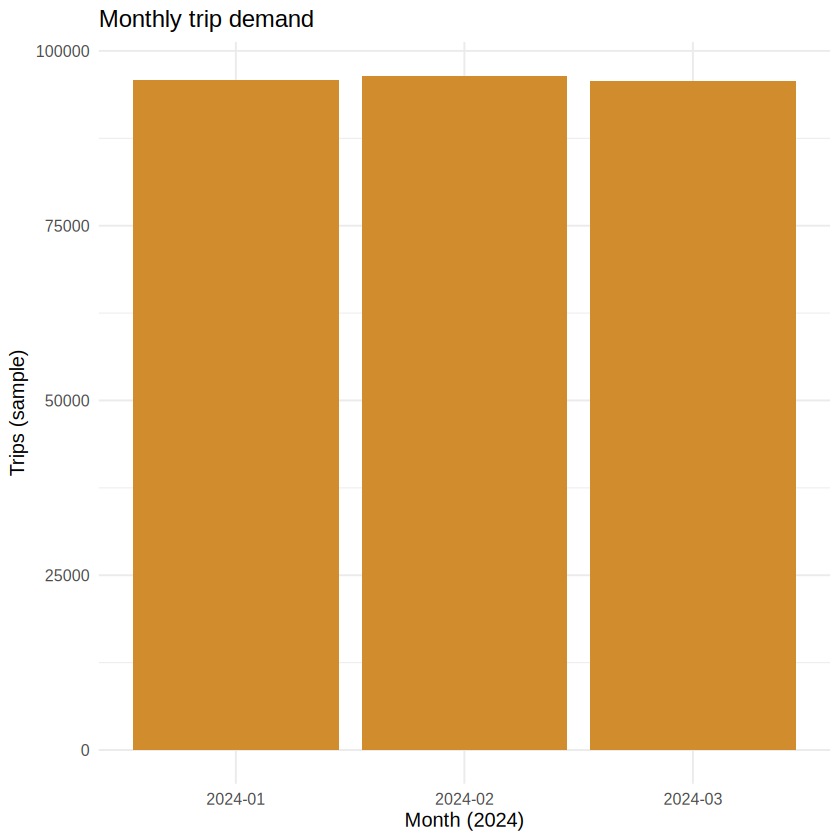

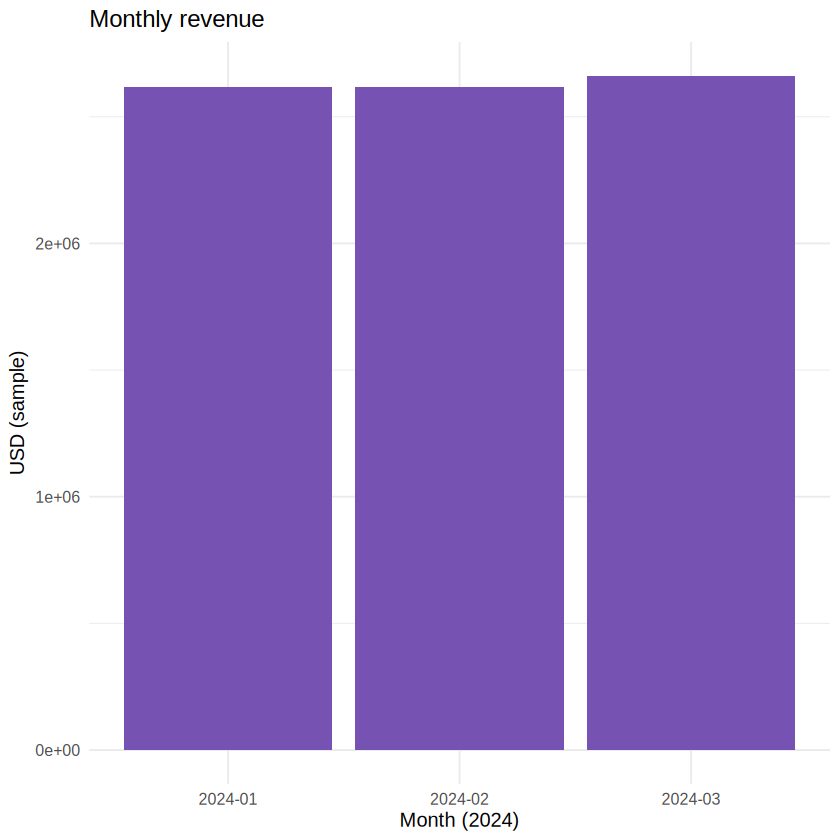

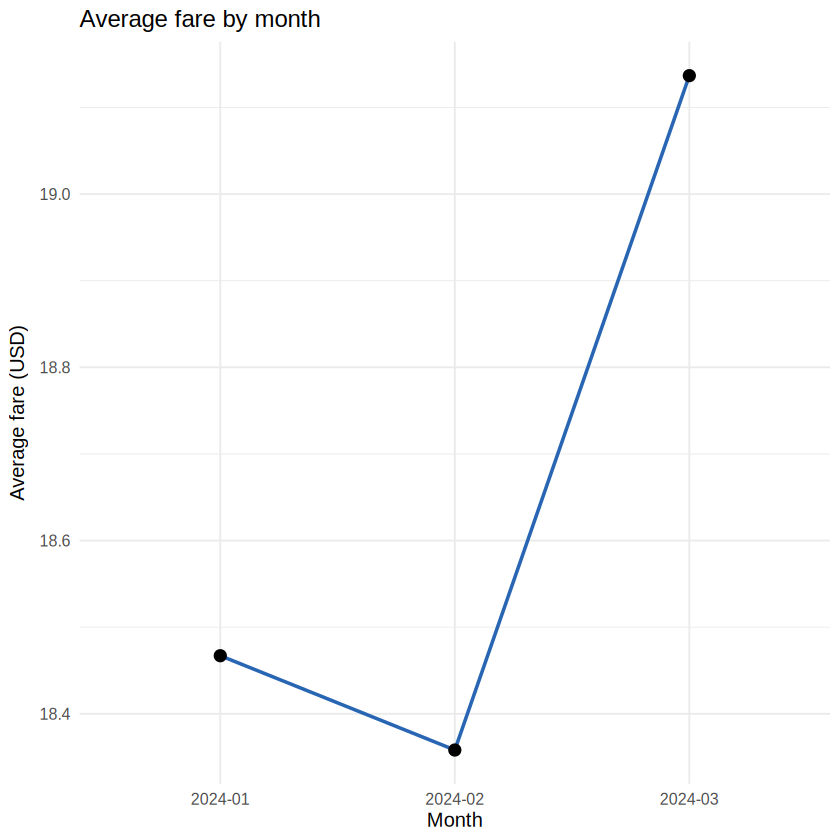

In [ ]:
ggplot(monthly, aes(month, trips)) + geom_col(fill = "#d08c2d") +
  labs(title = "Monthly trip demand", x = "Month (2024)", y = "Trips (sample)")
ggplot(monthly, aes(month, revenue)) + geom_col(fill = "#7653b2") +
  labs(title = "Monthly revenue", x = "Month (2024)", y = "USD (sample)")
ggplot(monthly, aes(month, avg_fare, group = 1)) + geom_line(linewidth = 1, color = "#2865b3") +
  geom_point(size = 3) + labs(title = "Average fare by month", x = "Month", y = "Average fare (USD)")

`geom_smooth()` using formula = 'y ~ x'


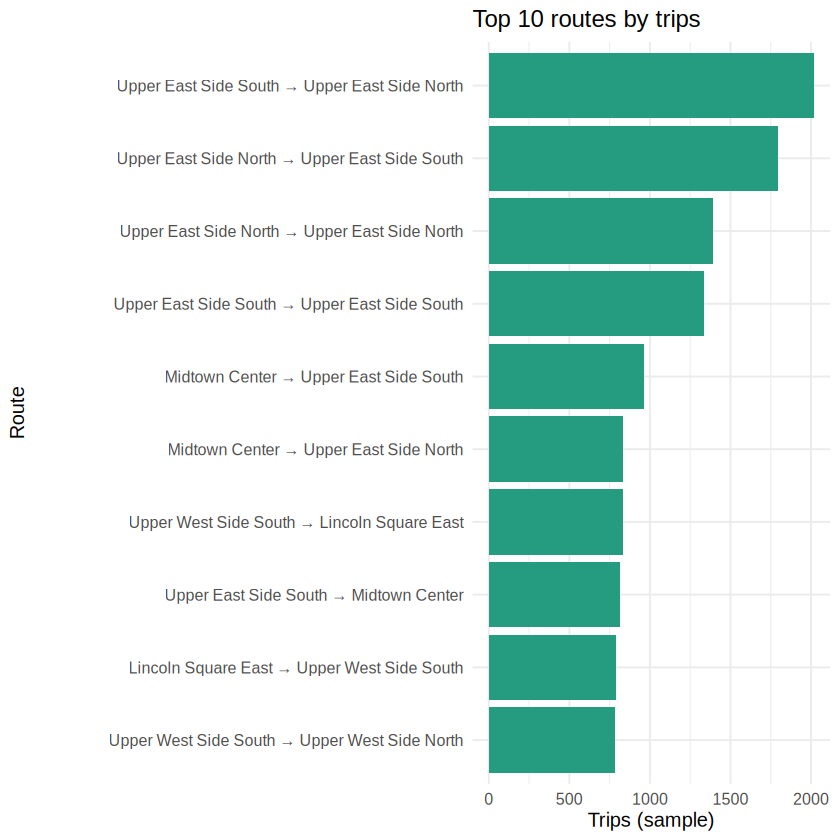

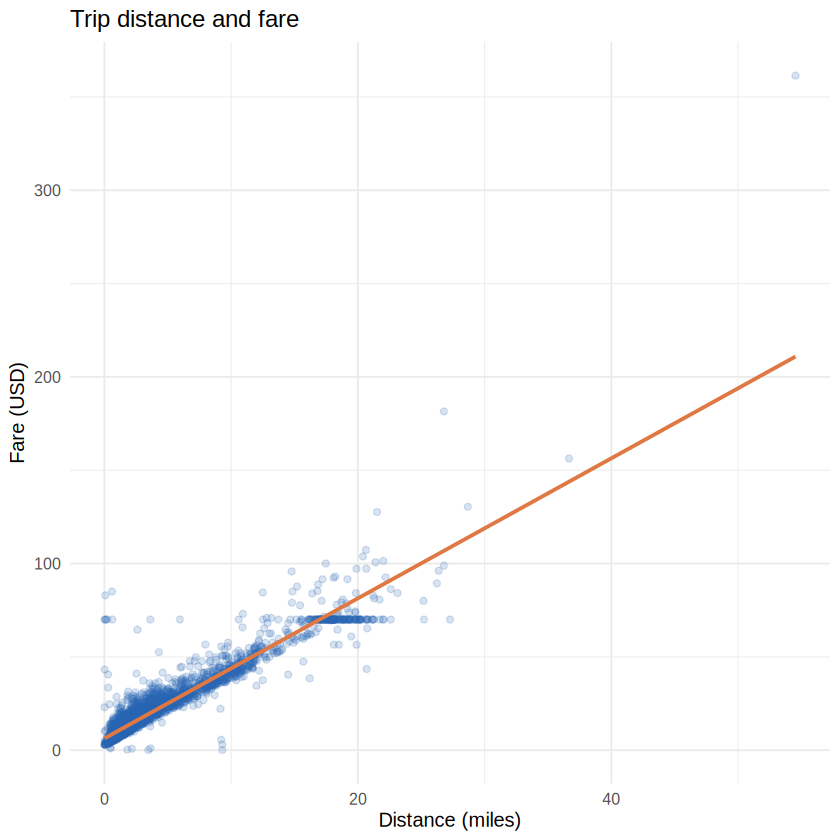

In [ ]:
top_routes <- head(routes, 10)
top_routes[, route := paste(pickup_zone, "→", dropoff_zone)]
ggplot(top_routes, aes(reorder(route, trips), trips)) + geom_col(fill = "#259b80") +
  coord_flip() + labs(title = "Top 10 routes by trips", x = "Route", y = "Trips (sample)")
set.seed(42)
plot_data <- trips[sample.int(nrow(trips), min(nrow(trips), 5000L))]
ggplot(plot_data, aes(trip_distance, fare_amount)) + geom_point(alpha = .18, color = "#2865b3") +
  geom_smooth(method = "lm", se = FALSE, color = "#e07843") +
  labs(title = "Trip distance and fare", x = "Distance (miles)", y = "Fare (USD)")

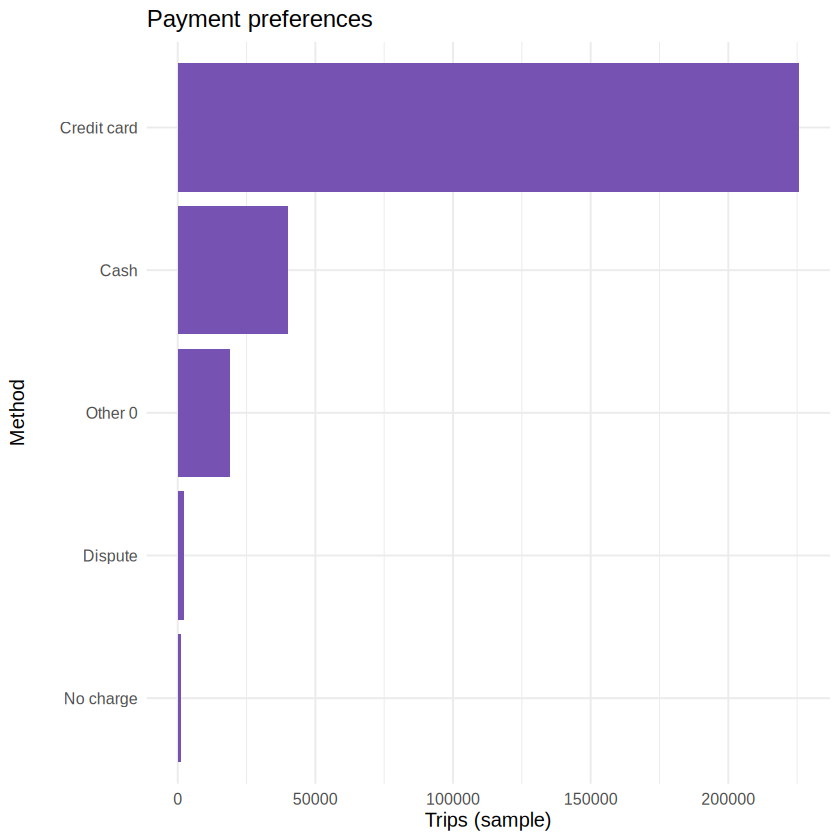

In [ ]:
payment_totals <- trips[!is.na(payment_type), .N, by = payment_type][order(-N)]
payment_totals[, payment_label := fifelse(payment_type == 1, "Credit card",
  fifelse(payment_type == 2, "Cash", fifelse(payment_type == 3, "No charge",
  fifelse(payment_type == 4, "Dispute", paste("Other", payment_type)))))]
ggplot(payment_totals, aes(reorder(payment_label, N), N)) + geom_col(fill = "#7653b2") +
  coord_flip() + labs(title = "Payment preferences", x = "Method", y = "Trips (sample)")

## 4. Functional, vectorized and data.table comparison

In [ ]:
x <- trips$fare_amount
base_functional <- function() sum(vapply(split(x, cut(x, breaks = c(-Inf, 10, 20, 40, Inf))), length, integer(1)))
base_vectorized <- function() sum(!is.na(x))
dt_optimized <- function() trips[!is.na(fare_amount), .N]
results_equal <- c(base_functional(), base_vectorized(), dt_optimized())
stopifnot(length(unique(results_equal)) == 1)
bench <- function(fn, times = 5L) {
  elapsed <- replicate(times, unname(system.time(fn())[["elapsed"]]))
  c(median_seconds = median(elapsed), min_seconds = min(elapsed))
}
benchmarks <- rbindlist(lapply(list(
  "Functional (split + vapply)" = base_functional,
  "Vectorized" = base_vectorized,
  "data.table" = dt_optimized
), function(fn) as.list(bench(fn))), idcol = "method")
print(benchmarks)
print(data.table(method = c("Functional", "Vectorized", "data.table"),
                 approx_input_MB = round(c(as.numeric(object.size(x)), as.numeric(object.size(x)), as.numeric(object.size(trips))) / 1024^2, 2)))

                        method median_seconds min_seconds
                        <char>          <num>       <num>
1: Functional (split + vapply)          0.012       0.011
2:                  Vectorized          0.001       0.001
3:                  data.table          0.003       0.002
       method approx_input_MB
       <char>           <num>
1: Functional             2.2
2: Vectorized             2.2
3: data.table            29.7


## 5. Sequential and parallel computation

In [ ]:
partitions <- split(trips[, .(month, pickup_zone, trip_distance, total_amount)], by = "month", keep.by = FALSE)
compute_part <- function(d) {
  z <- as.data.table(d)
  z[, .(trips = .N, revenue = sum(total_amount), average_distance = mean(trip_distance)), by = pickup_zone]
}
seq_time <- system.time(seq_result <- lapply(partitions, compute_part))[["elapsed"]]
cores <- min(2L, max(1L, parallel::detectCores(logical = FALSE) - 1L), length(partitions))
if (is.na(cores)) cores <- 1L
cl <- parallel::makeCluster(cores)
doParallel::registerDoParallel(cl)
par_execution <- tryCatch({
  t <- system.time(out <- foreach::foreach(d = partitions, .packages = "data.table", .export = "compute_part") %dopar% compute_part(d))[["elapsed"]]
  list(time = t, result = out)
}, finally = {parallel::stopCluster(cl); foreach::registerDoSEQ()})
par_time <- par_execution$time
stopifnot(isTRUE(all.equal(seq_result, par_execution$result, check.attributes = FALSE)))
comparison <- data.table(method = c("Sequential", "Parallel"), seconds = c(seq_time, par_time))
print(comparison)
cat("Speedup:", round(seq_time / max(par_time, .Machine$double.eps), 2), "x\n")

Warning message in e$fun(obj, substitute(ex), parent.frame(), e$data):
“already exporting variable(s): compute_part”


       method seconds
       <char>   <num>
1: Sequential   0.025
2:   Parallel   0.424
Speedup: 0.06 x


## 6. Performance benchmarking

                        method seconds
                        <char>   <num>
1: Functional (split + vapply)   0.012
2:                  Vectorized   0.001
3:                  data.table   0.003
4:                  Sequential   0.025
5:                    Parallel   0.424
Taxi data size (MB): 29.7 
Partitions: 3  | Parallel workers: 1 


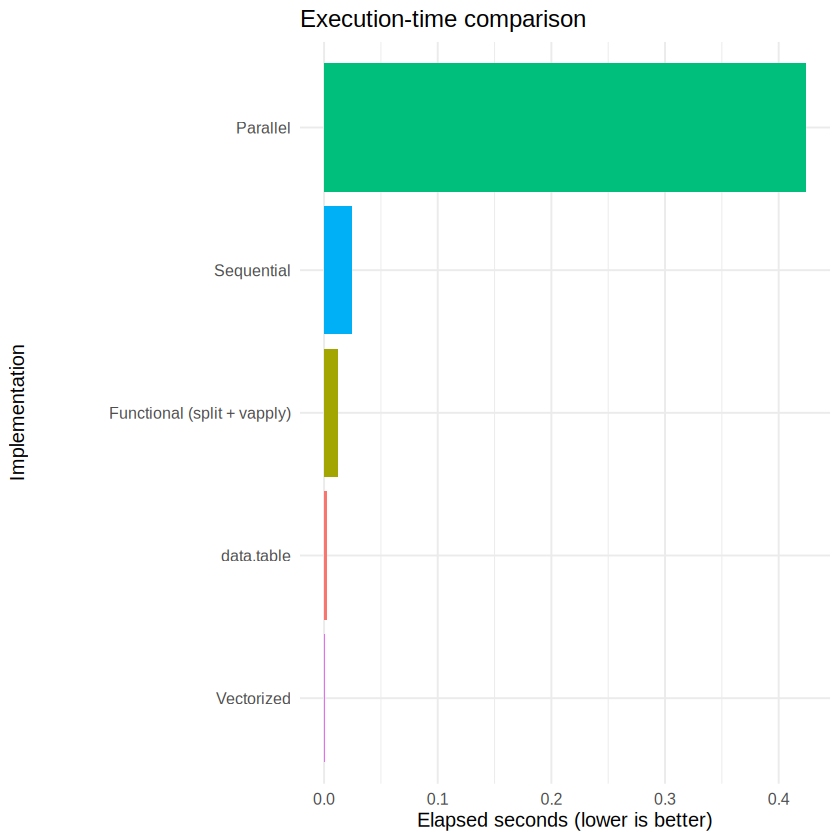

In [ ]:
time_plot <- rbindlist(list(
  benchmarks[, .(method, seconds = median_seconds)],
  comparison
), fill = TRUE)
print(time_plot)
ggplot(time_plot, aes(reorder(method, seconds), seconds, fill = method)) + geom_col(show.legend = FALSE) +
  coord_flip() + labs(title = "Execution-time comparison", x = "Implementation", y = "Elapsed seconds (lower is better)")
cat("Taxi data size (MB):", round(as.numeric(object.size(trips))/1024^2, 2), "\n")
cat("Partitions:", length(partitions), " | Parallel workers:", cores, "\n")

## 7. Observations and recommendation

The charts reveal peak pickup hours, busy weekdays, popular routes, revenue concentration, and payment preferences in the sampled taxi trips. Benchmark times depend on the Colab runtime, sampling, startup overhead, and workload. Parallel computation may be slower for small partitions because workers must start and data must be transferred.

**Recommendation:** Prefer `data.table` for memory-conscious grouped analysis and joins, use vectorized calculations for simple column operations, functional approaches for readable independent tasks, and parallel execution only after benchmarking substantial workloads.

## Conclusion
NYC taxi data was processed using efficient R techniques to study demand, fares, routes, and payments. Functional, vectorized, `data.table`, sequential, and parallel approaches were compared with measured execution times. The results demonstrate that optimization depends on task size, memory use, and parallel overhead.